# Breast Cancer Classification — Practical Task



## Practical task requirements

1. Load the breast cancer classification dataset from scikit-learn.
2. Train Decision Tree, Random Forest and Gradient Boosting models.
3. Use the same training/test split for a fair comparison.
4. Tune Random Forest hyperparameters and report the best combination.
5. Compare Accuracy, Precision, Recall, F1-score and ROC-AUC.
6. Plot ROC curves and display a final model comparison.



## 1. Import libraries

We import:
- `load_breast_cancer` to load the built-in dataset.
- `train_test_split` to create training and testing sets.
- The three classifiers required by the task.
- Evaluation metrics to compare model performance.
- `GridSearchCV` to tune Random Forest hyperparameters.
- `RocCurveDisplay` to plot ROC curves.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    GradientBoostingClassifier
)

## 2. Load the dataset

`load_breast_cancer(return_X_y=True)` returns:
- `X`: the input features.
- `y`: the target labels.

The dataset is built into scikit-learn, so no external CSV file is needed.

In [13]:
# 1. Load dataset
X, y = load_breast_cancer(return_X_y=True)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (569, 30)
Target shape: (569,)


## 3. Split into training and test sets

We use:
- `test_size=0.2`: 80% training data and 20% test data.
- `random_state=42`: makes the split reproducible.
- `stratify=y`: preserves the class proportions in both sets.

The same split is used for all three baseline models, which makes the comparison fair.

In [3]:
# 1. Load Breast Cancer dataset
from sklearn.datasets import load_breast_cancer

X, y = load_breast_cancer(return_X_y=True)

print("Dataset loaded successfully!")
print("Features:", X.shape)
print("Labels:", y.shape)

Dataset loaded successfully!
Features: (569, 30)
Labels: (569,)


In [4]:
# 2. Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


## 4. Define the three models

The dictionary stores the three classifiers required by the practical task:
- **Decision Tree:** learns decision rules by splitting the feature space.
- **Random Forest:** combines multiple decision trees.
- **Gradient Boosting:** builds an ensemble sequentially, with each stage improving on earlier errors.

`random_state=42` is used where supported for reproducibility. `BaggingClassifier` is imported to mirror the slide's imports, but it is not one of the three models requested for comparison.

In [5]:
# 3. Define models
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Boosting": GradientBoostingClassifier(random_state=42)
}

## 5. Train and compare the baseline models

For each model, the code:
1. Fits the model using `X_train` and `y_train`.
2. Predicts the class labels for `X_test`.
3. Gets the probability of the positive class for ROC-AUC.
4. Calculates Accuracy, Precision, Recall, F1-score and ROC-AUC.

The results are stored in a dictionary so they can be displayed together later.

In [6]:
# 4. Train and compare
results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)
    auc = roc_auc_score(y_test, probabilities)

    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": auc
    }

    print(f"\n{name}")
    print(f"Accuracy: {accuracy:.3f}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall: {recall:.3f}")
    print(f"F1 Score: {f1:.3f}")
    print(f"ROC-AUC: {auc:.3f}")


Decision Tree
Accuracy: 0.912
Precision: 0.956
Recall: 0.903
F1 Score: 0.929
ROC-AUC: 0.916

Random Forest
Accuracy: 0.956
Precision: 0.959
Recall: 0.972
F1 Score: 0.966
ROC-AUC: 0.994

Boosting
Accuracy: 0.956
Precision: 0.947
Recall: 0.986
F1 Score: 0.966
ROC-AUC: 0.991


## 6. Tune Random Forest hyperparameters

`GridSearchCV` tests combinations of Random Forest settings using 5-fold cross-validation.

The parameter grid includes:
- `n_estimators`: number of trees.
- `max_depth`: maximum depth of each tree.
- `min_samples_split`: minimum samples required to split a node.
- `min_samples_leaf`: minimum samples required at a leaf.

`scoring="roc_auc"` tells GridSearchCV to select the combination with the best mean cross-validation ROC-AUC. Tuning is performed on the training data only; the test set remains held out.

In [7]:
# 5. Tune Random Forest hyperparameters
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_

print("\nBest Random Forest Parameters:")
print(grid_search.best_params_)
print("Best cross-validation ROC-AUC:", round(grid_search.best_score_, 3))


Best Random Forest Parameters:
{'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best cross-validation ROC-AUC: 0.989


## 7. Evaluate the tuned Random Forest

After tuning, `best_rf` is the Random Forest model with the best cross-validation parameter combination.

We evaluate it on the same test set used for the baseline models. This allows a fair comparison without using the test data during tuning.

In [8]:
# 6. Evaluate tuned Random Forest
rf_predictions = best_rf.predict(X_test)
rf_probabilities = best_rf.predict_proba(X_test)[:, 1]

print("\nTuned Random Forest Results")
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions))
print("Recall:", recall_score(y_test, rf_predictions))
print("F1 Score:", f1_score(y_test, rf_predictions))
print("ROC-AUC:", roc_auc_score(y_test, rf_probabilities))


Tuned Random Forest Results
Accuracy: 0.956140350877193
Precision: 0.958904109589041
Recall: 0.9722222222222222
F1 Score: 0.9655172413793104
ROC-AUC: 0.9930555555555555


## 8. Plot ROC curves

The ROC curve plots the true positive rate against the false positive rate at different classification thresholds.

The AUC (area under the ROC curve) summarizes how well a model ranks positive cases above negative cases. A value closer to 1 indicates stronger discrimination; 0.5 is the level of random ranking.

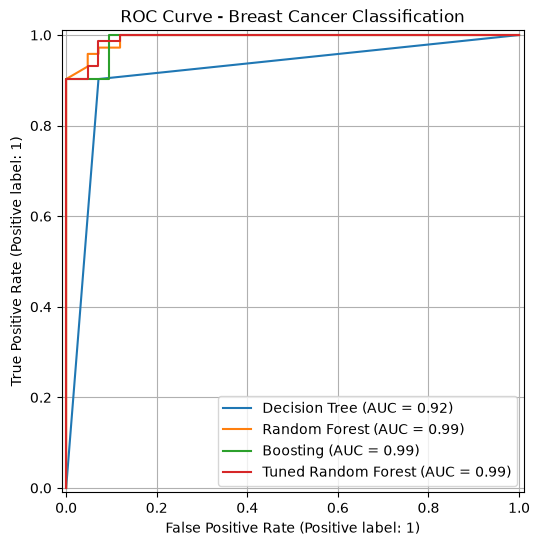

In [9]:
# 7. Plot ROC curves
plt.figure(figsize=(8, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model, X_test, y_test,
        name=name,
        ax=plt.gca()
    )

RocCurveDisplay.from_estimator(
    best_rf, X_test, y_test,
    name="Tuned Random Forest",
    ax=plt.gca()
)

plt.title("ROC Curve - Breast Cancer Classification")
plt.grid()
plt.show()

## 9. Final comparison table

We add the tuned Random Forest metrics to the results dictionary and convert the dictionary into a DataFrame.

This table provides the final comparison requested in the practical task.

In [10]:
# 8. Compare all model results
results["Tuned Random Forest"] = {
    "Accuracy": accuracy_score(y_test, rf_predictions),
    "Precision": precision_score(y_test, rf_predictions),
    "Recall": recall_score(y_test, rf_predictions),
    "F1": f1_score(y_test, rf_predictions),
    "ROC-AUC": roc_auc_score(y_test, rf_probabilities)
}

results_df = pd.DataFrame(results).T

print("\nFinal Model Comparison")
display(results_df.round(3))


Final Model Comparison


,Accuracy,Precision,Recall,F1,ROC-AUC
Decision Tree,0.912,0.956,0.903,0.929,0.916
Random Forest,0.956,0.959,0.972,0.966,0.994
Boosting,0.956,0.947,0.986,0.966,0.991
Tuned Random Forest,0.956,0.959,0.972,0.966,0.993


## 10. Conclusion

After running the notebook, use the actual values in the final comparison table to write your conclusion.

Your conclusion should state:
- Which model achieved the highest test ROC-AUC.
- Which model achieved the highest test F1-score.
- Whether Random Forest tuning improved the result compared with the default Random Forest.
- The best Random Forest hyperparameter combination selected by GridSearchCV.

Do not assume that the tuned Random Forest is automatically the best model. Base your conclusion on the measured test-set results.